### GMM Example

Gaussian Mixture Models can be used for clustering tasks. They work by dividing the data into a series of normal distributions, using probability to determine which distribution (cluster) each data point belongs to (Contreras Carrasco, 2024). This can be used for classification tasks such as customer segmentation. It is also applied to image segmentation tasks, which are common in medical imaging applications. For this example, we will use a GMM model to identify areas of hemorrhage in brain CT scans. This is useful for automatic detection of anomalies.

In [11]:
#load required libraries
import os
import numpy as np
import matplotlib.pyplot as plt

#GMM model from sklearn
from sklearn.mixture import GaussianMixture

#image processing functions from the associated skimage library
from skimage import io, color

### Define a function to load images from local folder

In [ ]:
def load_image_as_array(path):
    """Load images and convert them to numpy arrays."""
    img = io.imread(path) # skimage function to read image
    img = color.rgb2gray(img)  # convert to grayscale
    img_array = np.array(img) #convert to numpy array

    return img_array

### Define a function to apply GMM model to loaded images

In [ ]:
def segment_image_with_gmm(img_array, n_components):
    """Segment the image using Gaussian Mixture Model (GMM)."""
    h, w = img_array.shape
    pixels = img_array.reshape(-1, 1) #reshape the image to a 2D array of pixels

    # fit GMM
    gmm = GaussianMixture(n_components=n_components, covariance_type='tied', random_state=42, verbose=1)
    gmm.fit(pixels)
    labels = gmm.predict(pixels) #get labels for each pixel

    # sort cluster indices by mean intensity (easier to visually interpret)
    means = gmm.means_.flatten() #get cluster mean
    sorted_indices = np.argsort(means)  # low intensity -> high
    label_map = np.zeros_like(sorted_indices) #create mapping
    label_map[sorted_indices] = np.arange(n_components)

    # map labels to sorted indices
    sorted_labels = label_map[labels]

    # reshape to original image
    segmented = sorted_labels.reshape(h, w)
    
    return segmented


### Define a function to display the results

In [12]:
def show_segmentation(original, segmented):
    """Display the original and segmented images side by side."""
    plt.figure(figsize=(10, 5))

    #show the original image in grayscale
    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap='gray') #specify grayscale so matplotlib doesn't use a colormap
    plt.title('Original')
    plt.axis('off')

    # show the segmented image with a colormap assigned by the GMM
    plt.subplot(1, 2, 2)
    plt.imshow(segmented, cmap='viridis')
    plt.title('GMM Segmentation')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


### Test our functions!

Original images sourced from Kaggle: https://www.kaggle.com/datasets/felipekitamura/head-ct-hemorrhage

Initialization 0
Initialization converged.


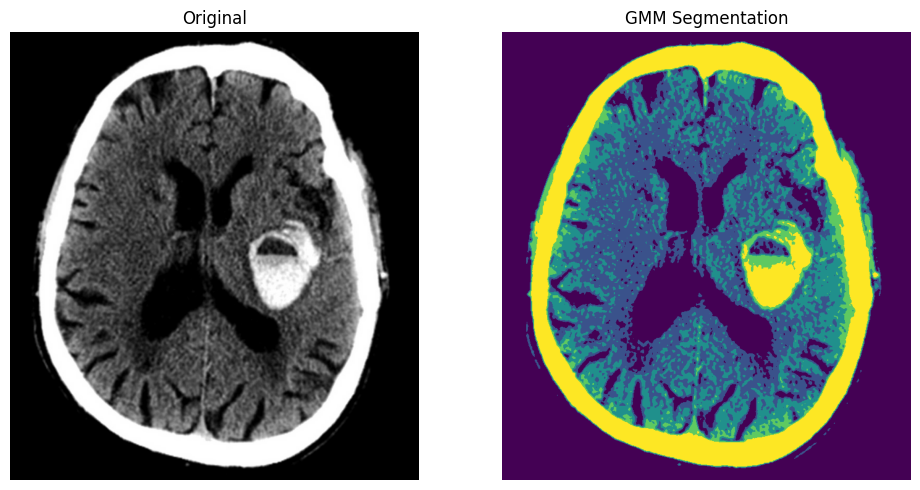

Initialization 0
Initialization converged.


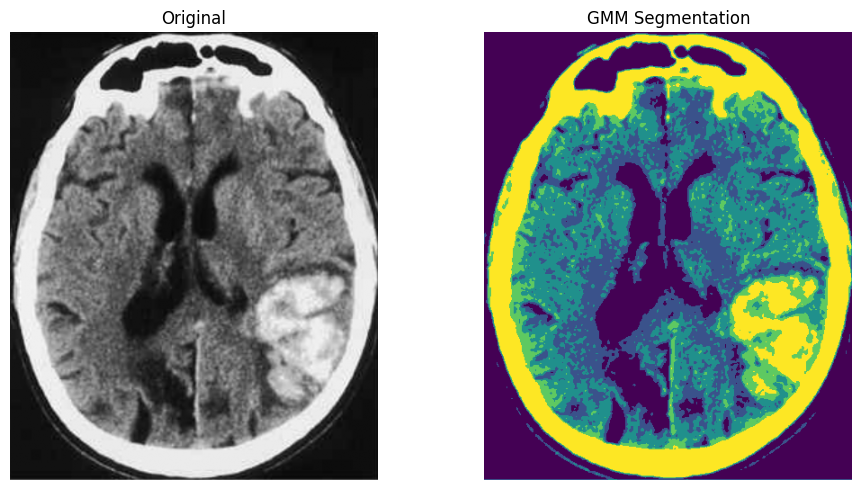

Initialization 0
Initialization converged.


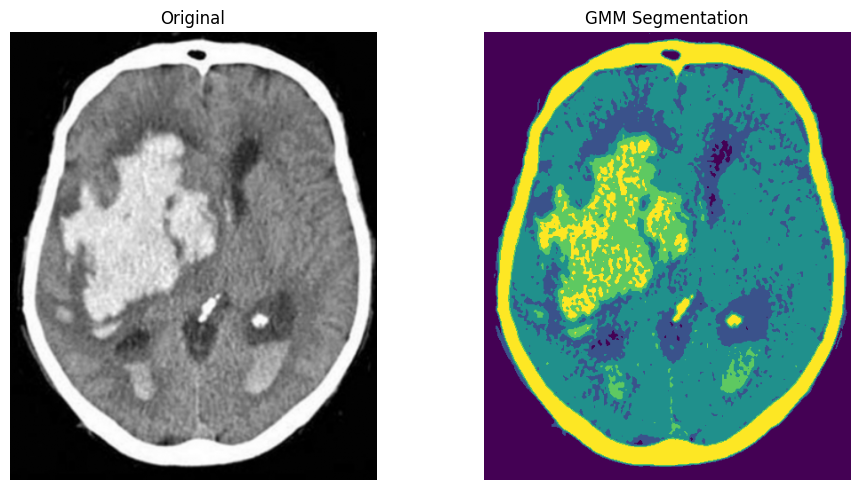

Initialization 0
Initialization converged.


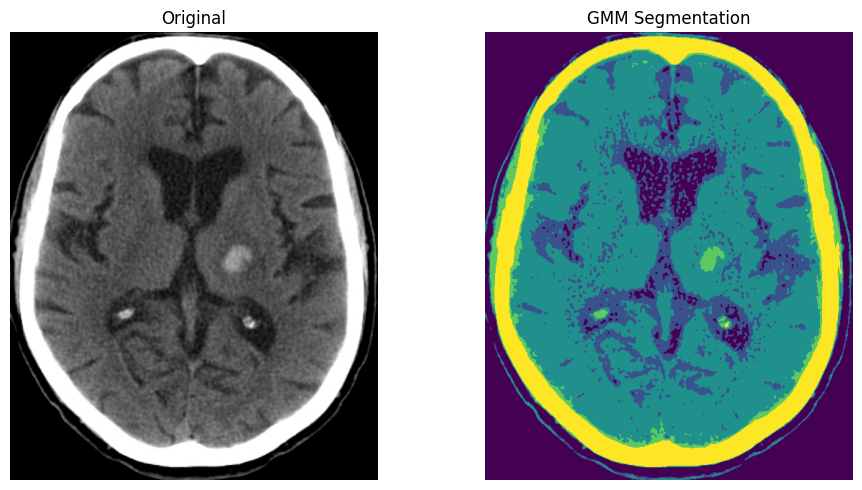

Initialization 0
Initialization converged.


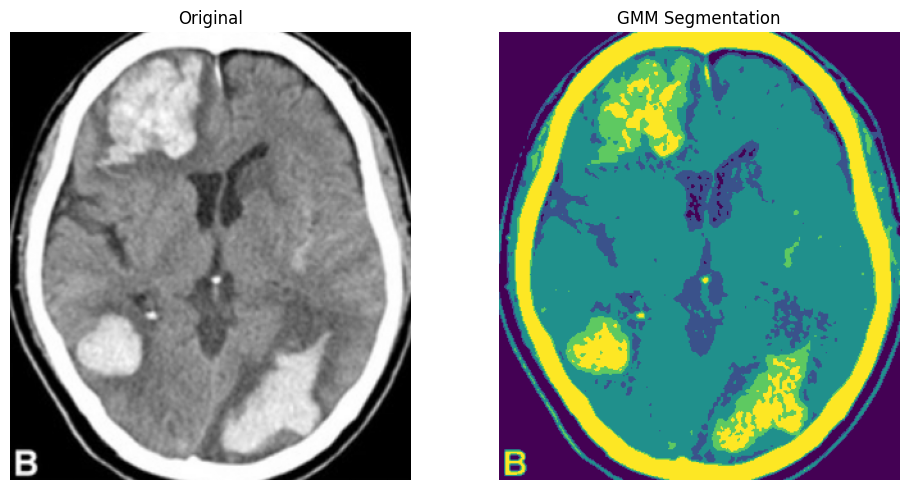

In [5]:
#get all image files in the specified folder
folder = 'images/' 
image_files = [f for f in os.listdir(folder) if f.lower().endswith(('.png'))]

for img_file in image_files:
    img_path = os.path.join(folder, img_file)
    img = load_image_as_array(img_path)
    segmented = segment_image_with_gmm(img, n_components=5)
    show_segmentation(img, segmented)

### We can then overlay these segments on the original images to highlight anomalies

In [ ]:
def overlay_mask_skimage(image, mask, target_label=None, alpha=0.4, bg_label=0):
    """
    Overlay GMM mask onto grayscale image using skimage's label2rgb.
    """
    if target_label is not None:
        mask = (mask == target_label).astype(int)
    else:
        mask = mask.astype(int)
    
    # label2rgb overlays a color-coded label map on top of a grayscale image
    overlay = label2rgb(mask, image=image, alpha=alpha, bg_label=bg_label, image_alpha=1.0)

    # Plot the result
    plt.figure(figsize=(10, 5))
    plt.imshow(overlay)
    plt.title(f"Overlay (Label {target_label if target_label is not None else 'All'})")
    plt.axis('off')
    plt.show()


### Let's test the overlay function on the same images

Initialization 0
Initialization converged.


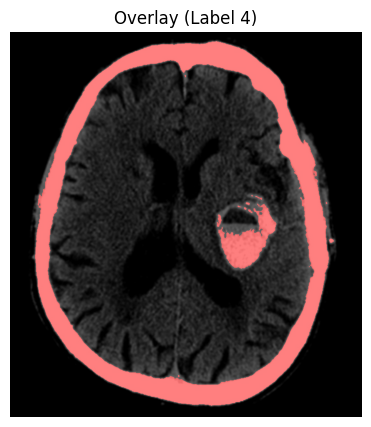

Initialization 0
Initialization converged.


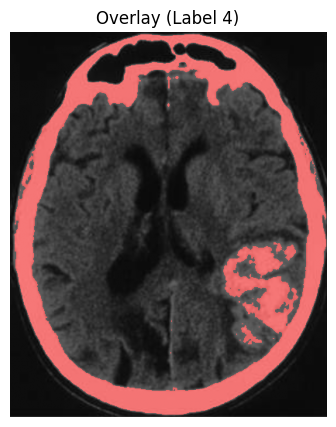

Initialization 0
Initialization converged.


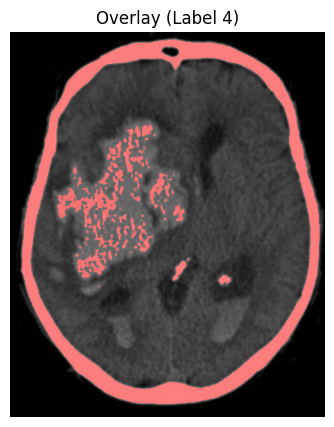

Initialization 0
Initialization converged.


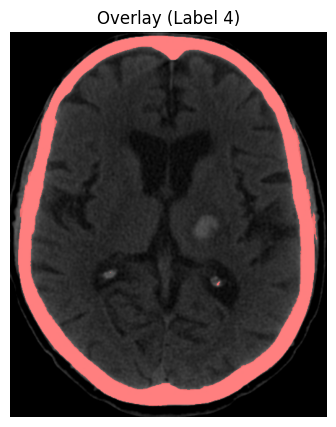

Initialization 0
Initialization converged.


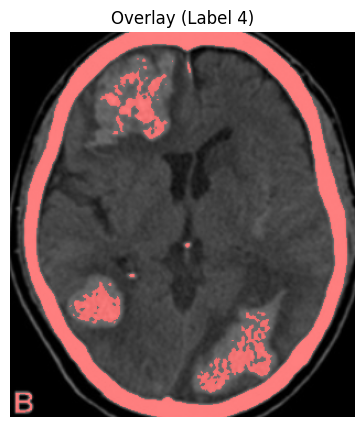

In [10]:
from skimage.color import label2rgb

for img_file in image_files:
    img_path = os.path.join(folder, img_file)
    img = load_image_as_array(img_path)
    segmented = segment_image_with_gmm(img, n_components=5)

    # Assume segmented is your GMM label map
    overlay_mask_skimage(img, segmented, target_label=4, alpha=0.5)  # Overlay label 4 with 50% transparency

### References:

- Contreras Carrasco, O. (2024). Gaussian Mixture Model Explained. Builtin.com. https://builtin.com/articles/gaussian-mixture-model
- Kitamura, F. (2018). Head CT - hemorrhage. Kaggle.com. https://www.kaggle.com/datasets/felipekitamura/head-ct-hemorrhage
- Raieli, S. (2024, April 10). Image Segmentation with Simple and Elegant Methods. Medium; Python in Plain English. https://python.plainenglish.io/image-segmentation-with-simple-and-elegant-methods-2c5920024b61
- Talasila, A. (2020, October). Generating Image Segmentation Masks - The Easy Way. Towards Data Science. https://towardsdatascience.com/generating-image-segmentation-masks-the-easy-way-dd4d3656dbd1/